In [1]:
import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [2]:
data=pd.read_csv("loan_approval_data.csv")

In [3]:
data.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [4]:
data.describe()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000
mean,501.220000,10852.571579,5082.455789,39.971579,1.474737,676.033684,1.950526,0.347263,9940.452632,24802.792632,20522.825263,48.000000
std,289.608451,5061.632859,2943.161570,11.139797,1.105067,71.346015,1.406246,0.144341,5860.736885,14345.696031,11504.142575,24.245322
min,1.000000,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,65.000000,36.000000,1015.000000,12.000000
25%,250.250000,6730.750000,2472.750000,30.250000,1.000000,616.250000,1.000000,0.220000,4760.250000,12698.250000,9806.250000,24.000000
50%,499.500000,10548.000000,5205.500000,40.000000,1.000000,678.000000,2.000000,0.340000,9880.500000,24321.000000,21210.500000,48.000000
75%,752.750000,15190.000000,7620.750000,49.000000,2.000000,737.000000,3.000000,0.480000,15074.500000,36947.000000,30263.000000,72.000000
max,1000.000000,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,39995.000000,84.000000


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    object 
 16  Educati

In [6]:
categorical_col=data.select_dtypes(include=["object"]).columns

In [7]:
numerical_col=data.select_dtypes(include=["float64"]).columns

In [8]:
from sklearn.impute import SimpleImputer

In [9]:
cat_imp=SimpleImputer( strategy="most_frequent")

In [10]:
data[categorical_col]=cat_imp.fit_transform(data[categorical_col])

In [11]:
num_imp=SimpleImputer(strategy="mean")

In [12]:
data[numerical_col]=num_imp.fit_transform(data[numerical_col])

In [13]:
data.isnull().sum()

Applicant_ID          0
Applicant_Income      0
Coapplicant_Income    0
Employment_Status     0
Age                   0
Marital_Status        0
Dependents            0
Credit_Score          0
Existing_Loans        0
DTI_Ratio             0
Savings               0
Collateral_Value      0
Loan_Amount           0
Loan_Term             0
Loan_Purpose          0
Property_Area         0
Education_Level       0
Gender                0
Employer_Category     0
Loan_Approved         0
dtype: int64

In [14]:
#EDA

In [15]:
gender_count=data["Gender"].value_counts()

([<matplotlib.patches.Wedge at 0x1ba845612b0>,
 [Text(-0.40814808922615514, 1.0214769391724117, 'yes'),
  Text(0.4081485438350891, -1.0214767575257386, 'no')],
 [Text(-0.22262623048699368, 0.5571692395485881, '62%'),
  Text(0.22262647845550312, -0.5571691404685846, '38%')])

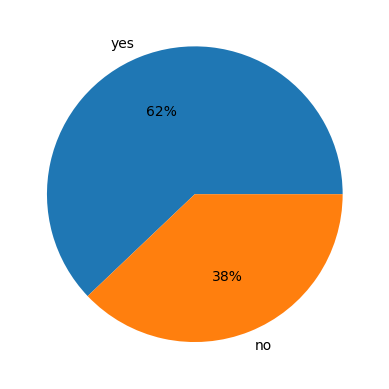

In [16]:
plt.pie(gender_count, autopct="%1.f%%",labels=["yes","no"])

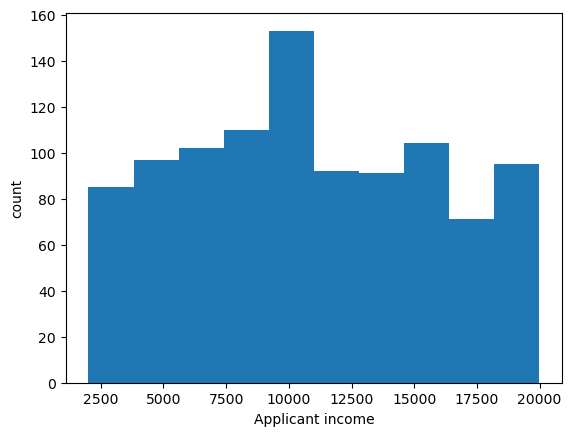

In [17]:
plt.hist(data["Applicant_Income"],bins=10)
plt.xlabel("Applicant income")
plt.ylabel("count")
plt.show()

In [ ]:
# categories

[Text(0, 0, '621'), Text(0, 0, '379')]

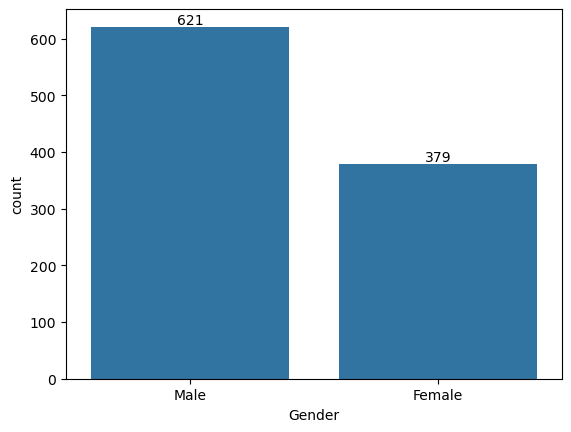

In [20]:
br=sns.barplot(gender_count)
br.bar_label(br.containers[0])

<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

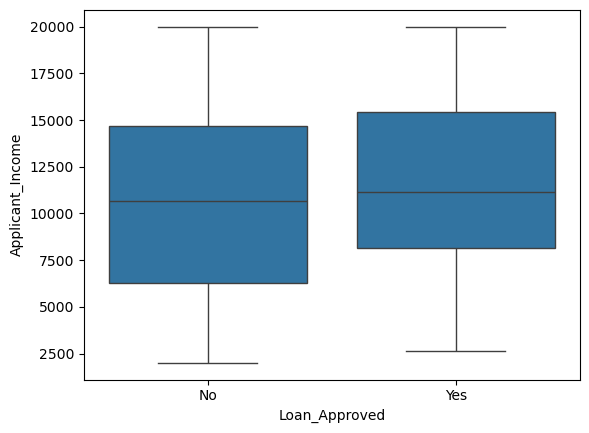

In [21]:
sns.boxplot(
    data=data,
    x="Loan_Approved",
    y="Applicant_Income"
)

In [ ]:
#relation of credict score with olan approval

<Axes: xlabel='Credit_Score', ylabel='Count'>

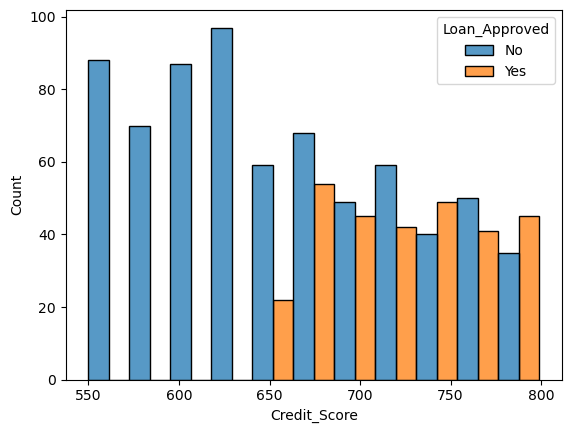

In [22]:
sns.histplot(
    data=data,
    hue="Loan_Approved",
    x="Credit_Score",
    multiple="dodge"
    
)

## Feature encoding

In [23]:
data=data.drop("Applicant_ID", axis=1)

In [24]:
data.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


In [25]:
from sklearn.preprocessing import LabelEncoder

In [26]:
le=LabelEncoder()
data["Education_Level"]=le.fit_transform(data["Education_Level"])

In [27]:
data.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,1,Female,Private,No
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,0,Male,Private,No
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,0,Female,Government,Yes
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,0,Female,Government,No
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,0,Male,Private,Yes


In [28]:

# Encoding

In [29]:
#labelEncoding

In [30]:
data.columns

Index(['Applicant_Income', 'Coapplicant_Income', 'Employment_Status', 'Age',
       'Marital_Status', 'Dependents', 'Credit_Score', 'Existing_Loans',
       'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term',
       'Loan_Purpose', 'Property_Area', 'Education_Level', 'Gender',
       'Employer_Category', 'Loan_Approved'],
      dtype='object')

In [31]:
'Employment_Status'
'Loan_Approved'

from sklearn.preprocessing import LabelEncoder,OneHotEncoder

In [32]:
lb=LabelEncoder()
data['Education_Level']=lb.fit_transform(data['Education_Level'])
data["Loan_Approved"]=lb.fit_transform(data["Loan_Approved"])

In [33]:
cols=['Marital_Status','Gender','Employer_Category','Employment_Status','Loan_Purpose','Property_Area']
hot=OneHotEncoder(drop="first", sparse_output=False,handle_unknown="ignore")
encoded=hot.fit_transform(data[cols])
encoded_df=pd.DataFrame(encoded,columns=hot.get_feature_names_out(cols),index=data.index)


In [34]:
hot.get_feature_names_out(cols)

array(['Marital_Status_Single', 'Gender_Male',
       'Employer_Category_Government', 'Employer_Category_MNC',
       'Employer_Category_Private', 'Employer_Category_Unemployed',
       'Employment_Status_Salaried', 'Employment_Status_Self-employed',
       'Employment_Status_Unemployed', 'Loan_Purpose_Car',
       'Loan_Purpose_Education', 'Loan_Purpose_Home',
       'Loan_Purpose_Personal', 'Property_Area_Semiurban',
       'Property_Area_Urban'], dtype=object)

In [35]:
encoded_df.head()

,Marital_Status_Single,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed,Employment_Status_Salaried,Employment_Status_Self-employed,Employment_Status_Unemployed,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban
0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [36]:
df=pd.concat([data.drop(columns=cols),encoded_df] , axis=1)

In [37]:
df.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Employer_Category_Unemployed,Employment_Status_Salaried,Employment_Status_Self-employed,Employment_Status_Unemployed,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban
0,17795.0,1387.0,51.0,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1,2860.0,2679.0,46.0,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,7390.0,2106.0,25.0,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,13964.0,8173.0,40.0,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,13284.0,4223.0,31.0,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Applicant_Income                 1000 non-null   float64
 1   Coapplicant_Income               1000 non-null   float64
 2   Age                              1000 non-null   float64
 3   Dependents                       1000 non-null   float64
 4   Credit_Score                     1000 non-null   float64
 5   Existing_Loans                   1000 non-null   float64
 6   DTI_Ratio                        1000 non-null   float64
 7   Savings                          1000 non-null   float64
 8   Collateral_Value                 1000 non-null   float64
 9   Loan_Amount                      1000 non-null   float64
 10  Loan_Term                        1000 non-null   float64
 11  Education_Level                  1000 non-null   int64  
 12  Loan_Approved        

# correlation heatmap

In [39]:
num_cols=df.select_dtypes(include="number")
corr_matrix= num_cols.corr()

In [40]:
corr_matrix

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Employer_Category_Unemployed,Employment_Status_Salaried,Employment_Status_Self-employed,Employment_Status_Unemployed,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban
Applicant_Income,1.000000,0.007545,-0.023988,-0.026658,-0.009818,-0.010457,-0.009107,-0.028358,0.018789,-0.024143,...,-0.011995,-0.000863,0.005609,0.001419,-0.083398,0.032794,0.074209,-0.031234,0.004845,-0.036260
Coapplicant_Income,0.007545,1.000000,0.014306,-0.026733,0.058423,0.012418,0.058078,-0.015047,0.009457,0.001596,...,-0.047929,-0.013517,-0.010462,0.023114,-0.020148,0.028000,0.016022,0.059549,-0.010058,0.030045
Age,-0.023988,0.014306,1.000000,-0.018767,-0.004212,0.023330,0.007903,-0.000986,0.037382,0.013502,...,0.072462,-0.000167,-0.011743,-0.009866,-0.025521,-0.006283,0.029865,0.037293,0.003100,-0.025661
Dependents,-0.026658,-0.026733,-0.018767,1.000000,-0.007687,-0.026338,0.011498,-0.004981,0.023004,-0.017409,...,-0.054147,-0.034611,0.079136,0.000396,-0.043685,-0.044642,0.027343,-0.005785,-0.032278,0.024082
Credit_Score,-0.009818,0.058423,-0.004212,-0.007687,1.000000,-0.007130,0.002338,-0.065353,0.007865,0.001002,...,-0.046087,-0.016627,-0.035896,-0.008344,-0.030142,0.026013,-0.008658,0.015324,-0.006946,0.004445
Existing_Loans,-0.010457,0.012418,0.023330,-0.026338,-0.007130,1.000000,0.047008,0.034435,-0.049916,-0.021035,...,0.045391,-0.004462,0.042772,-0.012356,-0.025228,-0.010035,0.001777,0.023212,-0.053971,0.035629
DTI_Ratio,-0.009107,0.058078,0.007903,0.011498,0.002338,0.047008,1.000000,0.004663,-0.009622,0.075784,...,0.026018,0.031658,-0.043904,0.022318,-0.020907,0.040432,-0.014125,-0.036648,0.044898,-0.006156
Savings,-0.028358,-0.015047,-0.000986,-0.004981,-0.065353,0.034435,0.004663,1.000000,0.015481,-0.012208,...,0.027178,0.022435,0.000668,0.006304,-0.009133,0.032558,-0.012217,-0.028948,0.005438,0.016833
Collateral_Value,0.018789,0.009457,0.037382,0.023004,0.007865,-0.049916,-0.009622,0.015481,1.000000,0.002660,...,-0.009655,-0.019882,0.000119,-0.041632,0.031112,0.040406,-0.050975,-0.007120,0.020061,0.007975
Loan_Amount,-0.024143,0.001596,0.013502,-0.017409,0.001002,-0.021035,0.075784,-0.012208,0.002660,1.000000,...,-0.026566,-0.003266,-0.072972,-0.007407,-0.006788,-0.006119,-0.000930,0.032498,0.040206,-0.050076


<Axes: >

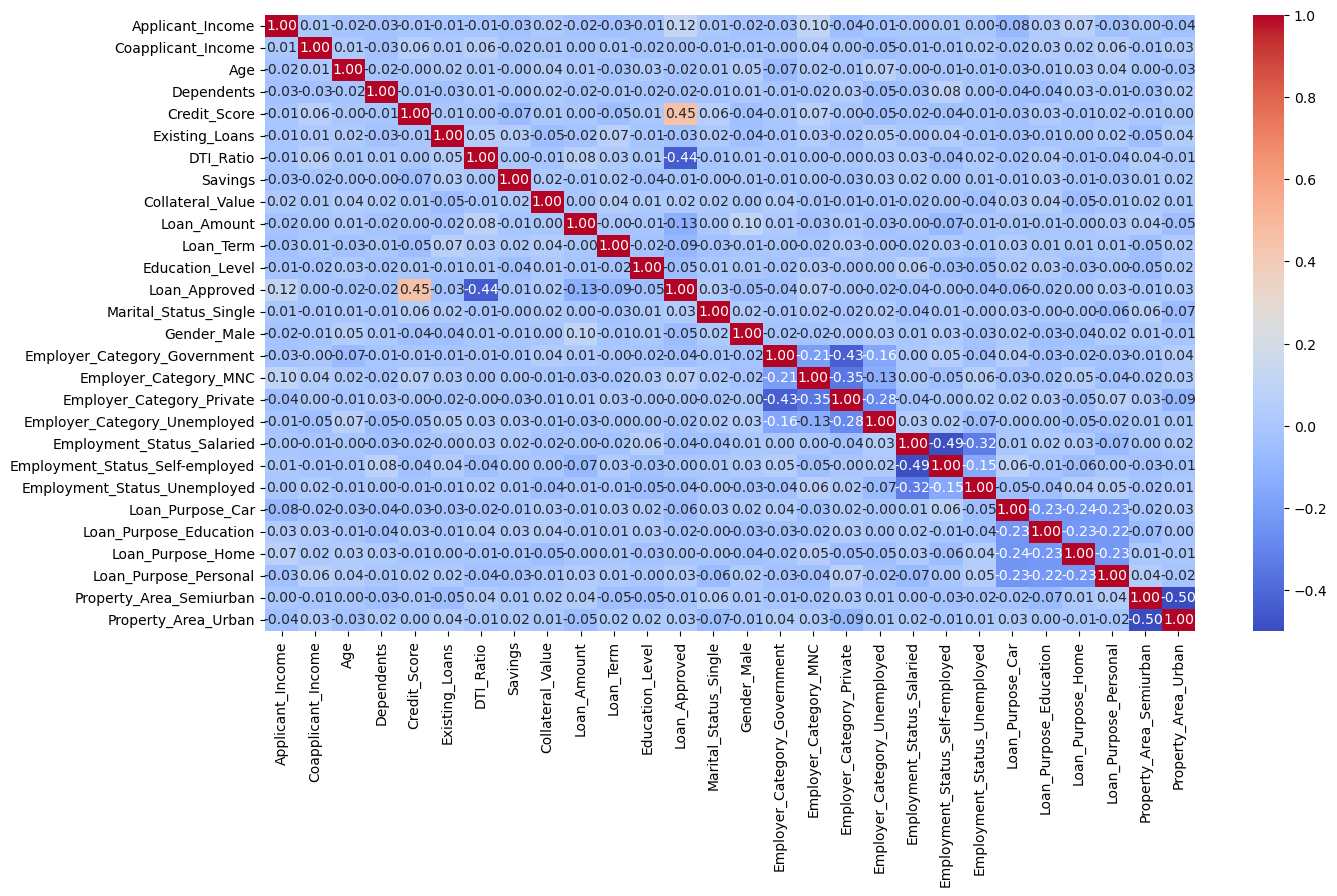

In [41]:
plt.figure(figsize=(15,8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

# train_test_split

In [42]:
x=df.drop(["Loan_Approved"], axis=1)
y=df["Loan_Approved"]

In [43]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [44]:
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=42,test_size=0.2)

In [45]:
x_train

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Employer_Category_Unemployed,Employment_Status_Salaried,Employment_Status_Self-employed,Employment_Status_Unemployed,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban
29,5890.000000,8041.0,31.000000,0.000000,603.000000,0.000000,0.110000,11906.0,8150.000000,29287.000000,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
535,4779.000000,529.0,50.000000,0.000000,614.000000,0.000000,0.210000,5369.0,5430.000000,14786.000000,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
695,10852.571579,8927.0,36.000000,0.000000,584.000000,4.000000,0.220000,3186.0,24802.792632,20522.825263,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
557,2384.000000,2113.0,39.971579,1.000000,726.000000,4.000000,0.340000,11882.0,48542.000000,13312.000000,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
836,5228.000000,5249.0,42.000000,1.000000,676.033684,1.950526,0.180000,17669.0,24802.792632,13906.000000,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,10755.000000,4107.0,59.000000,0.000000,560.000000,2.000000,0.347263,6806.0,5932.000000,20323.000000,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
270,2569.000000,5068.0,39.971579,1.474737,673.000000,1.000000,0.530000,3563.0,21699.000000,12280.000000,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
860,9783.000000,6099.0,31.000000,0.000000,703.000000,1.000000,0.347263,2575.0,48348.000000,26208.000000,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
435,16512.000000,3762.0,53.000000,1.000000,616.000000,1.000000,0.320000,14780.0,3598.000000,23191.000000,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [46]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled= scaler.transform(x_test)

In [47]:
from sklearn.linear_model import LogisticRegression

In [48]:
model=LogisticRegression()

In [49]:
model.fit(x_train_scaled,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [50]:
from sklearn.metrics import accuracy_score,recall_score,confusion_matrix,precision_score,f1_score

In [51]:
y_pred=model.predict(x_test)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [52]:
print("pricission ", precision_score(y_test,y_pred)*100)
print("recall", recall_score(y_test,y_pred)*100)
print("pricission ", f1_score(y_test,y_pred)*100)
print("pricission ", confusion_matrix(y_test,y_pred))
print("pricission ", accuracy_score(y_test,y_pred)*100)

pricission  37.67123287671233
recall 90.1639344262295
pricission  53.14009661835749
pricission  [[48 91]
 [ 6 55]]
pricission  51.5


In [53]:
#naive bays throm 

In [54]:
from sklearn.naive_bayes import GaussianNB

In [ ]:
gnb_model=GaussianNB()

In [ ]:
gnb_model.fit(x_train,y_train)

In [ ]:
y_pred= gnb_model.predict(x_test)

In [ ]:
print("pricission score",precision_score(y_test,y_pred))
print("recall_score", recall_score(y_test,y_pred))
print("confusion_matrix", confusion_matrix(y_test,y_pred))
